In [4]:
##### Figure 6: distribution of 30x30 exposure

from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import numpy as np
import pandas as pd
import rioxarray
from scipy.signal import savgol_filter
import rasterio
from rasterio.enums import Resampling
from matplotlib.ticker import MaxNLocator
import xarray as xr
import rasterio.features  
from matplotlib.colors import to_rgb
import sys

In [5]:
##### Load data

# Get the current working directory
cd = Path.cwd().parent
sys.path.append(str(cd))

# load helpers
from helpers.reproject_raster import reproject_raster, array_to_raster

# capital / labor / production rasters
capital_path = f"{cd}/Results/Raster_models/rescaled_capital_USD.tif"
capital_path_p10 = f"{cd}/Results/Raster_models/rescaled_capital_USD_p10.tif"
capital_path_p90 = f"{cd}/Results/Raster_models/rescaled_capital_USD_p90.tif"

labor_path = f"{cd}/Results/Raster_models/rescaled_jobs.tif"
labor_path_p10 = f"{cd}/Results/Raster_models/rescaled_jobs_p10.tif"
labor_path_p90 = f"{cd}/Results/Raster_models/rescaled_jobs_p90.tif"

production_path = f'{cd}/Data/total_production_tonnes_2020.tif'

# relative deprivation percentile rasters
rd_percentiles_national = f"{cd}/Data/relative_deprevation_percentiles_reprojected.tif"
rd_percentiles_global = f"{cd}/Data/global_relative_deprevation_percentiles_reprojected.tif"

# priority rasters (0 = not in top 30%, 1 = in top 30% not PA, 2 = in top 30% + PA)
biodiversity_with_PA = f"{cd}/Data/conservation_scenario.tif"

# country boundaries
country_shp = gpd.read_file(f"{cd}/Data/gadm_410-levels.gpkg", layer='ADM_0')
regions_shp = gpd.read_file(f"{cd}/Data/gadm_410-levels.gpkg", layer='ADM_1')

# Set file path to figure repo
FIG_DIR = Path(f"{cd}/Figures/")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
##### Data prep

# Resample to match conservation scneario (equal area projection)
production_arr = reproject_raster(production_path, resampling="sum")
production = array_to_raster(production_arr)

capital_arr = reproject_raster(capital_path, resampling="sum")
capital = array_to_raster(capital_arr)

labor_arr = reproject_raster(labor_path, resampling="sum")
labor = array_to_raster(labor_arr)

##### Align rasters 
def load_da(x):
    return x if isinstance(x, xr.DataArray) else rioxarray.open_rasterio(x, masked=True)

capital_da = load_da(capital)
labor_da = load_da(labor)
production_da = load_da(production)

# p10 / p90 rasters
def prep_ci(path):
    arr = reproject_raster(path, resampling="sum")
    return match_grid(load_da(array_to_raster(arr)), rd_national_da)

capital_p10_da = prep_ci(capital_path_p10)
capital_p90_da = prep_ci(capital_path_p90)
labor_p10_da = prep_ci(labor_path_p10)
labor_p90_da = prep_ci(labor_path_p90)

# load addtional rasters
rd_national_da = rioxarray.open_rasterio(rd_percentiles_national, masked=True)
rd_global_da = rioxarray.open_rasterio(rd_percentiles_global, masked=True)
biodiversity_da = rioxarray.open_rasterio(biodiversity_with_PA, masked=True)

def match_grid(da, target):
    return da.rio.reproject_match(target, resampling=Resampling.nearest)

capital_da = match_grid(capital_da, rd_national_da)
labor_da = match_grid(labor_da, rd_national_da)
production_da = match_grid(production_da, rd_national_da)
rd_global_da = match_grid(rd_global_da, rd_national_da)
biodiversity_da = match_grid(biodiversity_da, rd_national_da)

In [7]:
##### Define functions 

COLORS = {
    "Capital": "#2F7C87",
    "Labor": "#C96A3B",
    "Production": "#E5E5E5",
}
PRODUCTION_EDGE = "#C4C4C4"
REFERENCE_COLOR = "#888888"

def pct_by_percentile_within_mask(var_da, pctl_da, priority_mask):
    var = var_da.squeeze().values.astype(float)
    pctl = pctl_da.squeeze().values.astype(float)

    nodata_var = var_da.rio.nodata
    if nodata_var is not None:
        var = np.where(var == nodata_var, np.nan, var)
    nodata_pctl = pctl_da.rio.nodata
    if nodata_pctl is not None:
        pctl = np.where(pctl == nodata_pctl, np.nan, pctl)

    valid = ~np.isnan(var) & ~np.isnan(pctl) & (pctl >= 1) & (pctl <= 100) & priority_mask

    var_v = var[valid]
    pctl_v = np.round(pctl[valid]).astype(int)

    total = np.nansum(var_v)

    df = pd.DataFrame({"percentile": pctl_v, "value": var_v})
    grouped = df.groupby("percentile")["value"].sum().reindex(range(1, 101), fill_value=0)

    return (grouped / total) * 100 if total > 0 else grouped


def smooth(series, window=9, polyorder=2):
    smoothed = savgol_filter(series.values, window_length=window, polyorder=polyorder, mode="interp")
    return pd.Series(smoothed, index=series.index)


country_mask_cache = {}


def get_country_mask(gid0, target_da=rd_national_da):
    if gid0 in country_mask_cache:
        return country_mask_cache[gid0]

    geom = country_shp[country_shp["GID_0"] == gid0]

    geom_proj = geom.to_crs(target_da.rio.crs)
    transform = target_da.rio.transform()
    out_shape = target_da.squeeze().shape

    mask = rasterio.features.geometry_mask(
        geom_proj.geometry, out_shape=out_shape, transform=transform, invert=True
    )

    country_mask_cache[gid0] = mask
    return mask


priority_mask_full = biodiversity_da.squeeze().values >= 1


def build_mask(gid0=None):
    mask = get_country_mask(gid0) if gid0 is not None else np.ones_like(priority_mask_full, dtype=bool)
    return mask & priority_mask_full


def draw_exposure_line(ax, pctl_da, mask, title, xlabel, ylabel=None, legend=False):
    capital_pct_line = smooth(pct_by_percentile_within_mask(capital_da, pctl_da, mask))
    labor_pct_line = smooth(pct_by_percentile_within_mask(labor_da, pctl_da, mask))
    production_pct_line = smooth(pct_by_percentile_within_mask(production_da, pctl_da, mask))

    ax.fill_between(
        production_pct_line.index,
        production_pct_line.values,
        color=COLORS["Production"],
        alpha=0.8,
        zorder=1,
        label="Production",
    )
    ax.plot(
        production_pct_line.index,
        production_pct_line.values,
        color=PRODUCTION_EDGE,
        linewidth=1.2,
        zorder=2,
    )
    ax.plot(
        capital_pct_line.index,
        capital_pct_line.values,
        label="Capital",
        color=COLORS["Capital"],
        linewidth=2.2,
        zorder=4,
    )
    ax.plot(
        labor_pct_line.index,
        labor_pct_line.values,
        label="Labor",
        color=COLORS["Labor"],
        linewidth=2.2,
        zorder=4,
    )
    ax.axhline(
        1,
        color=REFERENCE_COLOR,
        linewidth=1.3,
        linestyle="--",
        zorder=4,
        label="Proportional distribution (1%)",
    )

    ax.set_xlabel(xlabel, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12)
    ax.set_ylim(bottom=0)
    ax.set_xlim(1, 100)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis="both", labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(title, fontweight="bold", fontsize=13)
    if legend:
        ax.legend(frameon=False, fontsize=10)

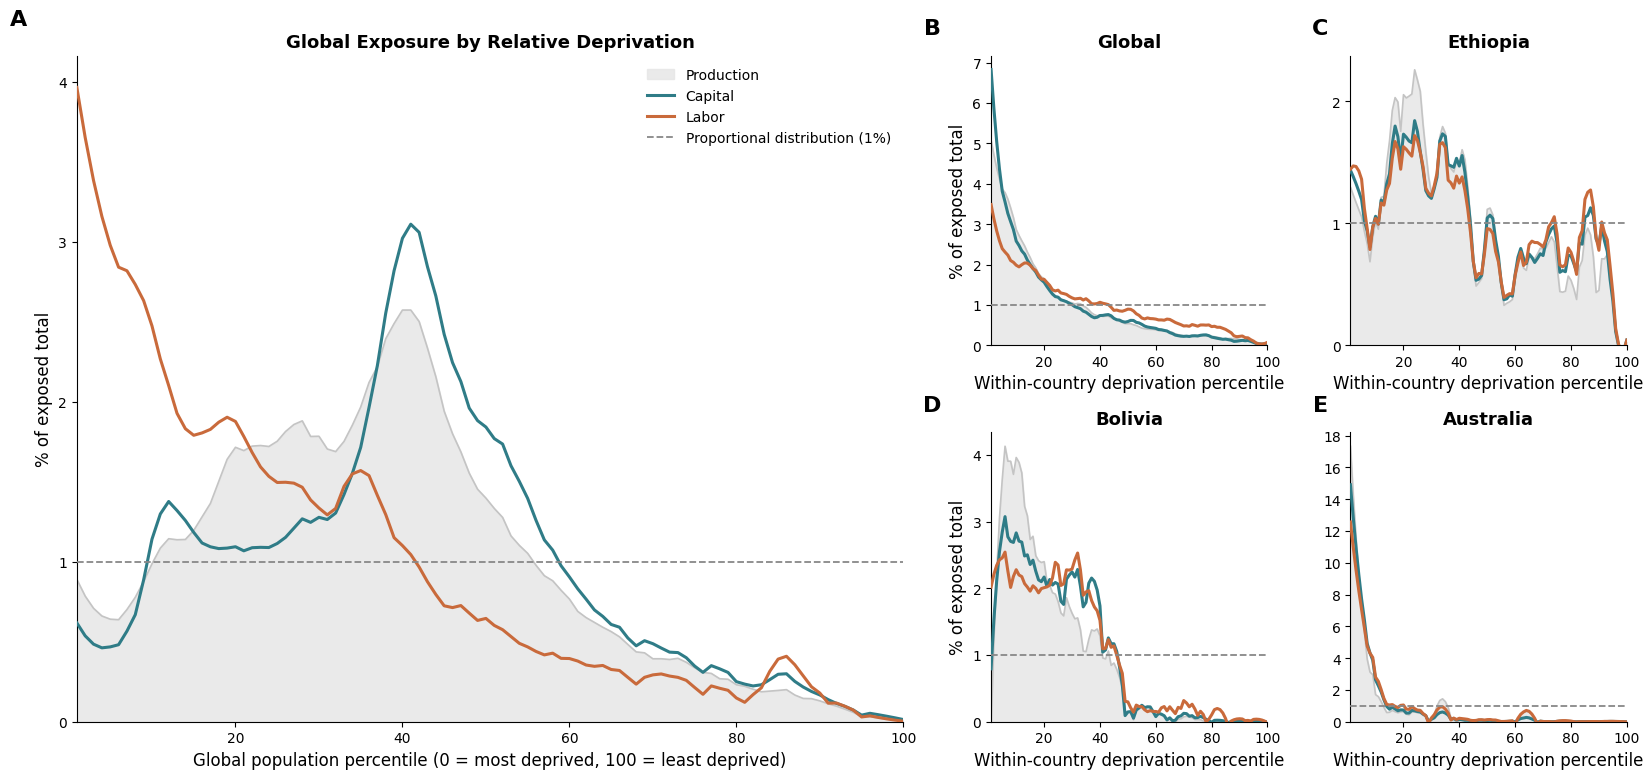

In [8]:
#####  Build figure 

# set countries 
COUNTRIES = ("ETH", "BOL", "AUS")
COUNTRY_NAMES = {"ETH": "Ethiopia", "BOL": "Bolivia", "AUS": "Australia"}

def add_panel_label(ax, letter, x=-0.02, y=1.08, fontsize=16):
    ax.text(
        x, y, letter,
        transform=ax.transAxes,
        fontsize=fontsize,
        fontweight="bold",
        va="bottom",
        ha="right",
    )

# plot
fig = plt.figure(figsize=(20, 9))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.3, 1], wspace=0.12)

# ---- Left: global exposure by global deprivation percentile ----
ax_left = fig.add_subplot(gs[0])
mask_global = build_mask(gid0=None)

draw_exposure_line(
    ax_left,
    rd_global_da,
    mask_global,
    title="Global Exposure by Relative Deprivation",
    xlabel="Global population percentile (0 = most deprived, 100 = least deprived)",
    ylabel="% of exposed total",
    legend=True,
)
add_panel_label(ax_left, "A", x=-0.06, y=1.04)

# ---- Right: 2x2 grid — national-percentile exposure ----
gs_right = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[1], wspace=0.3, hspace=0.3)

panel_specs = [("Global", None)] + [
    (COUNTRY_NAMES.get(c, c), c) for c in COUNTRIES
]

right_axes = [fig.add_subplot(gs_right[i // 2, i % 2]) for i in range(4)]

nat_xlabel = "Within-country deprivation percentile"
panel_letters = ["B", "C", "D", "E"]

for i, (ax, (panel_title, gid0)) in enumerate(zip(right_axes, panel_specs)):
    mask = build_mask(gid0)
    is_left_column = i % 2 == 0
    draw_exposure_line(
        ax,
        rd_national_da,
        mask,
        title=panel_title,
        xlabel=nat_xlabel,
        ylabel="% of exposed total" if is_left_column else None,
        legend=False,
    )
    add_panel_label(ax, panel_letters[i], x=-0.18 if is_left_column else -0.08, y=1.06)

fig.subplots_adjust(top=0.86, bottom=0.12)

plt.savefig(FIG_DIR / "Figure_6_distribution_of_exposure.tiff", dpi=300, bbox_inches="tight")

plt.show()

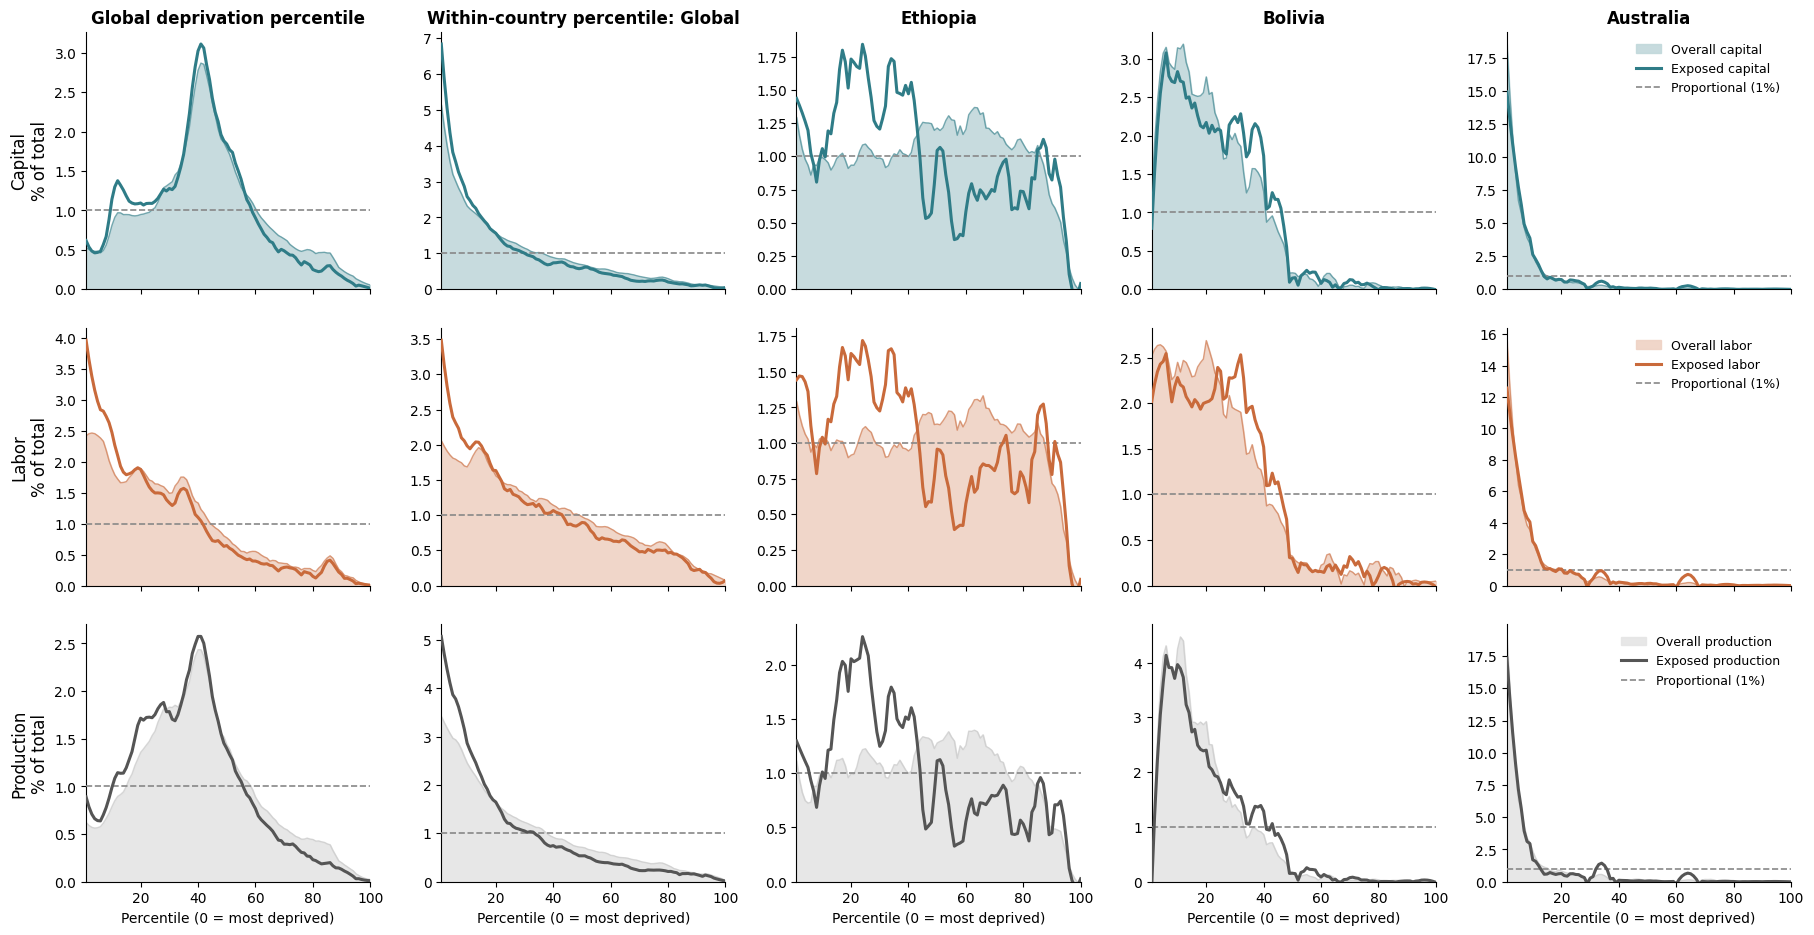

In [9]:
##### Figure SI: exposed vs overall capital, labor, production 
 
def build_mask_all(gid0=None):
    if gid0 is not None:
        return get_country_mask(gid0)
    return np.ones_like(priority_mask_full, dtype=bool)

# set specs 
def lighten(hex_color, amount=0.7):
    rgb = np.array(to_rgb(hex_color))
    return tuple(rgb + (1 - rgb) * amount)

VAR_SPECS = [
    ("Capital",    capital_da,    COLORS["Capital"],  lighten(COLORS["Capital"])),
    ("Labor",      labor_da,      COLORS["Labor"],    lighten(COLORS["Labor"])),
    ("Production", production_da, "#555555",          COLORS["Production"]),  
]

COL_SPECS = [
    ("Global deprivation percentile",      rd_global_da,   None),
    ("Within-country percentile: Global",  rd_national_da, None),
    ("Ethiopia", rd_national_da, "ETH"),
    ("Bolivia",  rd_national_da, "BOL"),
    ("Australia",   rd_national_da, "AUS"),
]

# compute masks once per column
col_masks = [(build_mask(g), build_mask_all(g)) for _, _, g in COL_SPECS]

# build figure 
fig, axes = plt.subplots(3, 5, figsize=(22, 10), sharey=False, sharex=True)

for r, (var_name, var_da, line_color, fill_color) in enumerate(VAR_SPECS):
    for c, (col_title, pctl_da, gid0) in enumerate(COL_SPECS):
        ax = axes[r, c]
        exp_mask, all_mask = col_masks[c]

        overall = smooth(pct_by_percentile_within_mask(var_da, pctl_da, all_mask))
        exposed = smooth(pct_by_percentile_within_mask(var_da, pctl_da, exp_mask))

        ax.fill_between(overall.index, overall.values, color=fill_color, alpha=0.9,
                        zorder=1, label=f"Overall {var_name.lower()}")
        ax.plot(overall.index, overall.values, color=PRODUCTION_EDGE if var_name == "Production" else line_color,
                lw=1.0, alpha=0.6, zorder=2)
        ax.plot(exposed.index, exposed.values, color=line_color, lw=2.2, zorder=4,
                label=f"Exposed {var_name.lower()}")
        ax.axhline(1, color=REFERENCE_COLOR, lw=1.2, ls="--", zorder=3,
                   label="Proportional (1%)")

        ax.set_xlim(1, 100)
        ax.set_ylim(bottom=0)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=10)

        if r == 0:
            ax.set_title(col_title, fontweight="bold", fontsize=12)
        if c == 0:
            ax.set_ylabel(f"{var_name}\n% of total", fontsize=12)  
        if r == 2:
            ax.set_xlabel("Percentile (0 = most deprived)", fontsize=10)
        if c == len(COL_SPECS) - 1:
            ax.legend(frameon=False, fontsize=9, loc="upper right")  

fig.subplots_adjust(hspace=0.15, wspace=0.25, top=0.93, bottom=0.08)
plt.savefig(FIG_DIR / "Figure_SI_exposed_vs_overall.tiff", dpi=300, bbox_inches="tight")
plt.show()

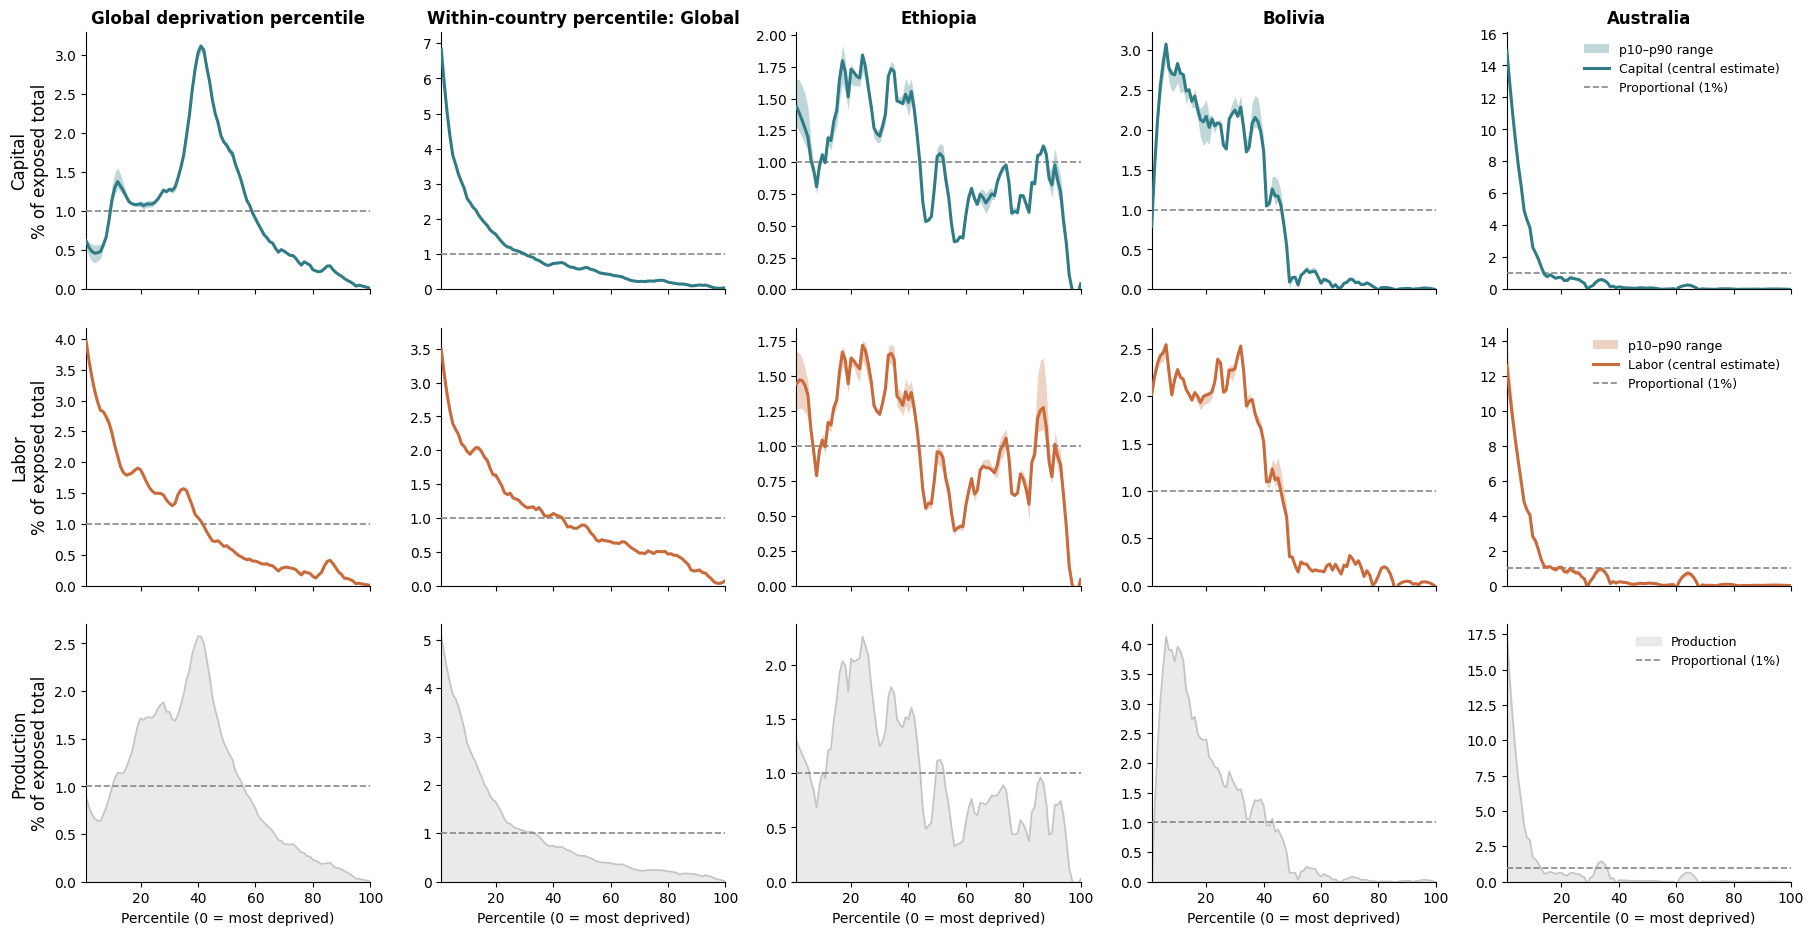

In [12]:
##### Figure SI: exposure distribution with p10-p90 uncertainty bands

# Rows: central estimate, p10, p90
ROW_VARS = [
    ("Capital",    capital_da,    capital_p10_da, capital_p90_da),
    ("Labor",      labor_da,      labor_p10_da,   labor_p90_da),
    ("Production", production_da, None,           None),
]

# Columns: region
COL_SPECS_CI = [
    ("Global deprivation percentile",      rd_global_da,   None),
    ("Within-country percentile: Global",  rd_national_da, None),
    ("Ethiopia",   rd_national_da, "ETH"),
    ("Bolivia",    rd_national_da, "BOL"),
    ("Australia",  rd_national_da, "AUS"),
]

col_masks_ci = [build_mask(g) for _, _, g in COL_SPECS_CI]

fig, axes = plt.subplots(3, 5, figsize=(22, 10), sharey=False, sharex=True)

for r, (var_name, var_da, p10_da, p90_da) in enumerate(ROW_VARS):
    for c, (col_title, pctl_da, gid0) in enumerate(COL_SPECS_CI):
        ax = axes[r, c]
        mask = col_masks_ci[c]
        central = smooth(pct_by_percentile_within_mask(var_da, pctl_da, mask))

        if var_name == "Production":
            ax.fill_between(central.index, central.values, color=COLORS["Production"],
                            alpha=0.8, zorder=1, label="Production")
            ax.plot(central.index, central.values, color=PRODUCTION_EDGE,
                    linewidth=1.2, zorder=2)
        else:
            lo = smooth(pct_by_percentile_within_mask(p10_da, pctl_da, mask))
            hi = smooth(pct_by_percentile_within_mask(p90_da, pctl_da, mask))

            band_lo = np.minimum(np.minimum(lo.values, hi.values), central.values)
            band_hi = np.maximum(np.maximum(lo.values, hi.values), central.values)

            ax.fill_between(central.index, band_lo, band_hi,
                            color=COLORS[var_name], alpha=0.3, linewidth=0, zorder=3,
                            label="p10–p90 range")
            ax.plot(central.index, central.values, color=COLORS[var_name],
                    linewidth=2.2, zorder=4, label=f"{var_name} (central estimate)")

        ax.axhline(1, color=REFERENCE_COLOR, linewidth=1.2, linestyle="--", zorder=3,
                   label="Proportional (1%)")

        ax.set_xlim(1, 100)
        ax.set_ylim(bottom=0)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=10)

        if r == 0:
            ax.set_title(col_title, fontweight="bold", fontsize=12)
        if c == 0:
            ax.set_ylabel(f"{var_name}\n% of exposed total", fontsize=12)
        if r == len(ROW_VARS) - 1:
            ax.set_xlabel("Percentile (0 = most deprived)", fontsize=10)
        if c == len(COL_SPECS_CI) - 1:
            ax.legend(frameon=False, fontsize=9, loc="upper right")

fig.subplots_adjust(hspace=0.15, wspace=0.25, top=0.93, bottom=0.08)
plt.savefig(FIG_DIR / "Figure_SI_exposure_distribution_CI.tiff", dpi=300, bbox_inches="tight")
plt.show()